# Voice AI agent on the Fluke API

Fluke places the call from a Brazilian number, inside the Brazilian network. Your AI agent joins the call over SIP. This notebook uses OpenAI Realtime; any SIP-capable AI works the same way (step 7).

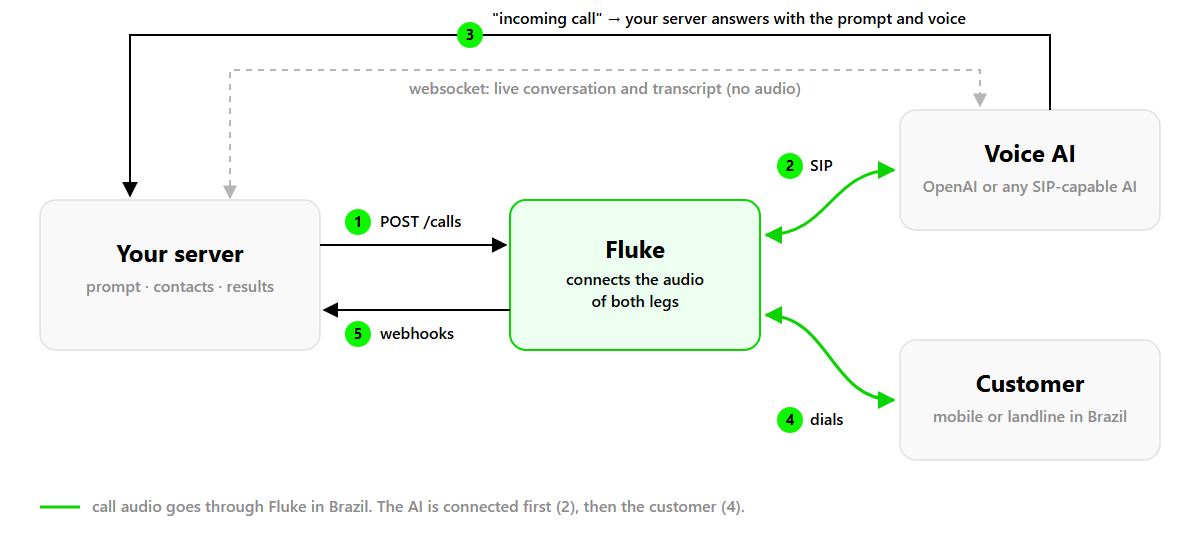

You need: a Fluke API key and a Fluke landline number, plus an OpenAI API key and project. Everything goes in `.env` (template in `.env.example`).

## 0. Setup

In [ ]:
import os
import pandas as pd
import requests
from dotenv import load_dotenv

load_dotenv()

BASE = "https://echo.flu.ke/api/v1"
HEADERS = {"x-api-key": os.environ["FLUKE_API_KEY"]}
FLUKE_NUMBER = os.environ["FLUKE_NUMBER"]   # Fluke number that places the calls (caller ID)

OPENAI = {"Authorization": f"Bearer {os.environ['OPENAI_API_KEY']}"}
AI_SIP = f"sip:{os.environ['OPENAI_PROJECT_ID']}@sip.api.openai.com;transport=tls"

## 1. Account and number
Prepaid balance (BRL) and the number the customer will see on the screen.

In [ ]:
balance = requests.get(f"{BASE}/billing/balance", headers=HEADERS).json()["data"]
number = requests.get(f"{BASE}/dids/{FLUKE_NUMBER}", headers=HEADERS).json()["data"]["did"]

{"balance (BRL)": round(balance["availableBalance"], 2), "caller ID": number["fullNumber"], "status": number["status"]}

## 2. Set up the AI
Everything on the AI side: prompt, the server that answers the AI, a public URL and the webhooks. With another AI provider this part changes; the call itself does not.

### Prompt
Everything the AI knows about the call. In production your system builds this text for each contact. The example confirms a technician visit, in Brazilian Portuguese; replace it with your use case.

In [ ]:
PROMPT = """
Você é a Lia, assistente virtual da Empresa Exemplo. Fale português do Brasil, com frases curtas, tom simpático e direto. Nunca invente informações.

Situação: você está ligando para a Maria Souza para confirmar a visita técnica marcada para amanhã, entre 9h e 12h, no endereço cadastrado.

A ligação começa quando a pessoa atende e diz "alô". Responda na hora.

Passo 1. Cumprimente e pergunte se está falando com a Maria. Se não for ela, pergunte se ela pode atender agora; se não puder, agradeça e encerre.
Passo 2. Explique a visita em uma frase e pergunte se o horário continua bom.
Passo 3. Se ela confirmar, agradeça e diga que o técnico avisa quando estiver a caminho.
Passo 4. Se ela não puder, pergunte qual dia e período desta semana funcionam e repita a resposta para confirmar.
Passo 5. Despeça-se e use a ferramenta end_call.

Se perguntarem se você é um robô, diga que é uma assistente virtual. Se a pessoa pedir para falar com alguém da equipe, diga que um atendente vai retornar e encerre.
"""
VOICE = "marin"

### Server that answers the AI

When Fluke connects the call over SIP, OpenAI notifies this server and waits for an answer. The server accepts the call with the prompt and follows the conversation. It also receives Fluke's webhooks.

In production this is your backend. Here it runs inside the notebook.

In [ ]:
import json, queue, threading, time
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer
from websockets.exceptions import ConnectionClosed
from websockets.sync.client import connect

LINES = queue.Queue()   # live conversation
EVENTS = []             # Fluke webhooks
ACCEPTED = set()        # OpenAI may resend the same notification

END_CALL = {"type": "function", "name": "end_call", "description": "Hang up after saying goodbye.",
            "parameters": {"type": "object", "properties": {}}}


def accept(call_id):
    r = requests.post(f"https://api.openai.com/v1/realtime/calls/{call_id}/accept", headers=OPENAI, json={
        "type": "realtime",
        "model": "gpt-realtime",
        "instructions": PROMPT,
        "audio": {"input": {"transcription": {"model": "gpt-4o-transcribe", "language": "pt"}},
                  "output": {"voice": VOICE}},
        "tools": [END_CALL],
    })
    if not r.ok:
        LINES.put((call_id, "⚠️", f"OpenAI rejected the call: {r.status_code} {r.text}"))
        LINES.put((call_id, "end", ""))
        return
    try:
        with connect(f"wss://api.openai.com/v1/realtime?call_id={call_id}", additional_headers=OPENAI) as ws:
            for msg in ws:
                ev = json.loads(msg)
                if ev["type"] == "conversation.item.input_audio_transcription.completed":
                    LINES.put((call_id, "👤", ev["transcript"].strip()))
                elif ev["type"] == "response.output_audio_transcript.done":
                    LINES.put((call_id, "🤖", ev["transcript"].strip()))
                elif ev["type"] == "response.function_call_arguments.done" and ev["name"] == "end_call":
                    time.sleep(1.5)
                    requests.post(f"https://api.openai.com/v1/realtime/calls/{call_id}/hangup", headers=OPENAI)
    except ConnectionClosed:
        pass  # OpenAI closes the websocket when the call ends
    except Exception as e:
        LINES.put((call_id, "⚠️", f"websocket error: {e!r}"))
    LINES.put((call_id, "end", ""))


class Server(BaseHTTPRequestHandler):
    protocol_version = "HTTP/1.1"

    def log_message(self, *args):
        pass

    def do_GET(self):
        self.reply()

    def do_POST(self):
        body = json.loads(self.rfile.read(int(self.headers.get("Content-Length") or 0)) or b"{}")
        self.reply()
        if self.path == "/openai" and body.get("type") == "realtime.call.incoming":
            call_id = body["data"]["call_id"]
            if call_id not in ACCEPTED:
                ACCEPTED.add(call_id)
                threading.Thread(target=accept, args=(call_id,), daemon=True).start()
        elif self.path == "/fluke":
            EVENTS.append({"time": time.strftime("%H:%M:%S"), **body})

    def reply(self):
        self.send_response(200)
        self.send_header("Content-Length", "2")
        self.end_headers()
        self.wfile.write(b"ok")


if "server" not in globals():
    server = ThreadingHTTPServer(("127.0.0.1", 8765), Server)
    threading.Thread(target=server.serve_forever, daemon=True).start()
print("local server on port 8765")

### Public URL

OpenAI and Fluke need to reach the server over the internet. For the demo, a temporary tunnel: tunnelmole if Node is installed (no time limit), otherwise pinggy (only needs ssh, lasts 60 min). In production, put your backend URL in `PUBLIC_URL` in `.env`.

In [ ]:
import re, shutil, subprocess

PUBLIC_URL = os.environ.get("PUBLIC_URL")

if not PUBLIC_URL:
    npx = shutil.which("npx")
    if npx:
        cmd, pattern = [npx, "-y", "tunnelmole@latest", "8765"], r"https://[a-z0-9-]+\.tunnelmole\.net"
    else:
        cmd = ["ssh", "-p", "443", "-o", "StrictHostKeyChecking=accept-new", "-o", "ServerAliveInterval=20",
               "-R0:127.0.0.1:8765", "a.pinggy.io"]
        pattern = r"https://[a-z0-9-]+\.free\.pinggy\.net"
    subprocess.Popen(cmd, stdout=open("tunnel.log", "w"), stderr=subprocess.STDOUT, stdin=subprocess.DEVNULL)
    for _ in range(60):
        found = re.search(pattern, open("tunnel.log", errors="ignore").read())
        if found:
            PUBLIC_URL = found.group(0)
            break
        time.sleep(1)

PUBLIC_URL

### Point the webhooks

Tell Fluke and OpenAI where to send notifications. Fluke is configured through the API, once per account. In OpenAI, paste the printed URL in the dashboard: Settings → Project → Webhooks, event `realtime.call.incoming`.

Note: the Fluke webhook applies to the whole account. If the account already sends events to another system, use a test account.

In [ ]:
r = requests.post(f"{BASE}/webhooks/configure", headers=HEADERS, json={"webhookUrl": f"{PUBLIC_URL}/fluke"})
print(r.status_code, r.json())

print("\nOpenAI webhook:", f"{PUBLIC_URL}/openai")

## 3. Call a customer

The AI goes in `bridgeTo` and is connected first; the customer goes in `to`. When the customer picks up, the AI is already on the line and answers the "alô" right away. The customer sees `from`, a Brazilian number.

In [ ]:
PHONE = "11999999999"   # customer's mobile or landline, Brazilian format with area code

payload = {
    "from": FLUKE_NUMBER,
    "bridgeTo": AI_SIP,
    "to": PHONE,
    "metadata": {"contact": "Maria Souza", "order": "OS-1234"},
}

LINES.queue.clear()   # clear the previous conversation

r = requests.post(f"{BASE}/calls", headers=HEADERS, json=payload)
print(r.status_code, r.json())
call_id = r.json()["data"]["callId"]

In [ ]:
# Live conversation
while True:
    try:
        _, who, text = LINES.get(timeout=1)
    except queue.Empty:
        failed = [e for e in EVENTS if e["type"] == "call_failed" and e["data"]["callId"] == call_id]
        if failed:
            print("Call did not complete:", failed[0]["data"].get("failureReason"))
            break
        continue
    if who == "end":
        print("· call ended")
        break
    print(who, text)

## 4. Webhooks
Fluke notifies your server on every call state change. The last one carries duration and cost; this is where your system records the result.

In [ ]:
for _ in range(30):  # the final webhook arrives a few seconds later
    if any(e["type"] in ("call_completed", "call_failed") and e["data"]["callId"] == call_id for e in EVENTS):
        break
    time.sleep(1)

pd.DataFrame([{
    "time": e["time"],
    "event": e["type"],
    "status": e["data"].get("status"),
    "duration (s)": e["data"].get("durationSeconds"),
    "cost (BRL)": e["data"].get("cost"),
} for e in EVENTS if e["data"].get("callId") == call_id])

## 5. Result
`GET /calls/{callId}` returns the final state of the call.

In [ ]:
call = requests.get(f"{BASE}/calls/{call_id}", headers=HEADERS).json()["data"]
{k: call.get(k) for k in ["status", "durationSeconds", "billedSeconds", "cost", "failureReason", "sipResponseCode", "metadata"]}

## 6. Contact list and outcomes

The same call from step 3, fired for each contact on the list. Calls run at the same time, each with its own AI session.

The table at the end shows, per call, whether the customer answered, was busy or did not answer, with the SIP code from the Brazilian network.

In [ ]:
contacts = [
    {"name": "Maria Souza", "phone": PHONE},
    {"name": "Carlos Lima", "phone": "11988888888"},   # replace with a second number
]

LINES.queue.clear()
ids = []
for c in contacts:
    payload = {"from": FLUKE_NUMBER, "bridgeTo": AI_SIP, "to": c["phone"], "metadata": {"contact": c["name"]}}
    r = requests.post(f"{BASE}/calls", headers=HEADERS, json=payload)
    print(c["name"], "→", r.status_code, r.json())
    if r.ok:
        ids.append(r.json()["data"]["callId"])

In [ ]:
# Live conversations, tagged by call
call_no = {}
while True:
    try:
        ai, who, text = LINES.get(timeout=1)
    except queue.Empty:
        done = [i for i in ids
                if any(e["type"] in ("call_completed", "call_failed") and e["data"]["callId"] == i for e in EVENTS)]
        if len(done) == len(ids):
            print("· all calls ended")
            break
        continue
    n = call_no.setdefault(ai, len(call_no) + 1)
    print(f"[call {n}]", "· ended" if who == "end" else f"{who} {text}")

In [ ]:
# Outcome per call. Leg A = bridgeTo (the AI); leg B = to (the customer).
OUTCOME = {"B_BUSY": "busy", "B_NO_ANSWER": "no answer",
           "A_BUSY": "AI busy", "A_NO_ANSWER": "AI did not answer", "TIMEOUT": "timeout"}

rows = []
for i in ids:
    c = requests.get(f"{BASE}/calls/{i}", headers=HEADERS).json()["data"]
    rows.append({
        "contact": (c.get("metadata") or {}).get("contact"),
        "to": c.get("to"),
        "outcome": "answered" if c["status"] == "COMPLETED" else OUTCOME.get(c.get("failureReason"), c.get("failureReason") or c["status"]),
        "SIP code": c.get("sipResponseCode"),
        "duration (s)": c.get("durationSeconds"),
        "cost (BRL)": c.get("cost"),
    })

outcomes = pd.DataFrame(rows)
display(outcomes)
outcomes["outcome"].value_counts(normalize=True).mul(100).round(1).rename("% of calls")

## 7. Your AI

Only `bridgeTo` changes:

| AI | `bridgeTo` |
|---|---|
| OpenAI | `sip:proj_XXXX@sip.api.openai.com;transport=tls` |
| ElevenLabs | `sip:+55NUMBER@sip.rtc.elevenlabs.io;transport=tls` |
| LiveKit, Vapi, Retell | the platform's SIP URI |
| Asterisk / FreeSWITCH | `sip:agent@IP` |

Docs: https://fluke-5a9f9325.mintlify.app/en/guides/making-calls